# Детекція об'єктів у приміщенні: YOLOv9s на Indoor Objects Detection

Ноутбук для запуску в Google Colab або Kaggle Notebooks (**Runtime -> Change runtime type -> GPU**).

План:
1. імпорт бібліотек і перевірка GPU;
2. завантаження датасету (формат YOLO, вже розділений на train / valid / test);
3. розвідувальний аналіз даних (EDA);
4. YAML-конфігурація і навчання **YOLOv9s** (transfer learning з COCO);
5. аналіз кривих навчання;
6. оцінка на valid і test: mAP, precision, recall, F1 по класах;
7. матриця помилок і найчастіші плутанини класів;
8. висновки, критика архітектури, шляхи покращення.

## 1. Імпорт бібліотек і робоче середовище

In [1]:
!pip install -q ultralytics kagglehub

In [2]:
import random
import shutil
from pathlib import Path

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Основні гіперпараметри (EPOCHS / FRACTION можна зменшити для швидкої перевірки)
MODEL_NAME = 'yolov9s.pt'
EPOCHS = 60
IMGSZ = 640
BATCH = 16
PATIENCE = 15   # early stopping: зупинка, якщо fitness не росте 15 епох
FRACTION = 1.0  # частка тренувального набору
RUN_NAME = 'yolov9s_indoor'

if torch.cuda.is_available():
    DEVICE = 0
    print('GPU:', torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
    print('Apple MPS')
else:
    DEVICE = 'cpu'
    print('УВАГА: GPU не знайдено, навчання буде дуже повільним. Увімкніть GPU у налаштуваннях середовища.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4


## 2. Завантаження даних

Датасет [Indoor Objects Detection](https://www.kaggle.com/datasets/thepbordin/indoor-object-detection) завантажуємо через `kagglehub`. Структура (формат YOLO):

```
<dataset>/
  data.yaml
  train/images, train/labels
  valid/images, valid/labels
  test/images,  test/labels
```
У кожному `.txt` файлі один об'єкт = один рядок: `class_id x_center y_center width height` (координати нормалізовані до 0..1).

In [3]:
dataset_path = Path(kagglehub.dataset_download('thepbordin/indoor-object-detection'))
print('Dataset:', dataset_path)

with open(dataset_path / 'data.yaml') as f:
    src_cfg = yaml.safe_load(f)
CLASS_NAMES = src_cfg['names']
NC = len(CLASS_NAMES)
print(NC, 'класів:', CLASS_NAMES)

SPLITS = {'train': 'train', 'valid': 'valid', 'test': 'test'}
for split in SPLITS:
    imgs = [p for p in (dataset_path / split / 'images').iterdir() if p.is_file()]
    lbls = list((dataset_path / split / 'labels').glob('*.txt'))
    print(f'{split:6s} зображень: {len(imgs):5d} | файлів розмітки: {len(lbls):5d}')

Dataset: /kaggle/input/datasets/thepbordin/indoor-object-detection
10 класів: ['door', 'cabinetDoor', 'refrigeratorDoor', 'window', 'chair', 'table', 'cabinet', 'couch', 'openedDoor', 'pole']
train  зображень:  1012 | файлів розмітки:  1008
valid  зображень:   230 | файлів розмітки:   230
test   зображень:   107 | файлів розмітки:   104


## 3. Знайомство з даними

Читаємо всі файли розмітки та будуємо таблицю з усіма рамками: клас, розмір, площа.

In [4]:
rows = []
img_stats = []
for split in SPLITS:
    for lbl_path in sorted((dataset_path / split / 'labels').glob('*.txt')):
        lines = [l.split() for l in lbl_path.read_text().splitlines() if l.strip()]
        img_stats.append({'split': split, 'file': lbl_path.stem, 'n_boxes': len(lines)})
        for l in lines:
            cls, xc, yc, w, h = int(l[0]), *map(float, l[1:5])
            rows.append({'split': split, 'file': lbl_path.stem, 'cls': cls, 'name': CLASS_NAMES[cls],
                         'xc': xc, 'yc': yc, 'w': w, 'h': h, 'area': w * h})
boxes = pd.DataFrame(rows)
imgs_df = pd.DataFrame(img_stats)

print('Усього рамок:', len(boxes))
print('Зображень без жодного об\'єкта (порожня розмітка):')
print(imgs_df[imgs_df.n_boxes == 0].groupby('split').size())
print('\nОб\'єктів на зображення:')
print(imgs_df.groupby('split').n_boxes.describe().round(2))

Усього рамок: 7331
Зображень без жодного об'єкта (порожня розмітка):
split
train    116
valid     31
dtype: int64

Об'єктів на зображення:
        count  mean   std  min  25%  50%  75%   max
split                                              
test    104.0  5.29  3.12  1.0  3.0  5.0  7.0  16.0
train  1008.0  5.45  6.28  0.0  1.0  3.0  8.0  54.0
valid   230.0  5.60  6.10  0.0  1.0  3.5  8.0  36.0


split,train,valid,test
name,,,
door,479,97,34
cabinetDoor,3178,765,179
refrigeratorDoor,689,192,2
window,403,91,63
chair,204,49,87
table,228,40,47
cabinet,179,32,52
couch,27,1,58
openedDoor,78,13,20


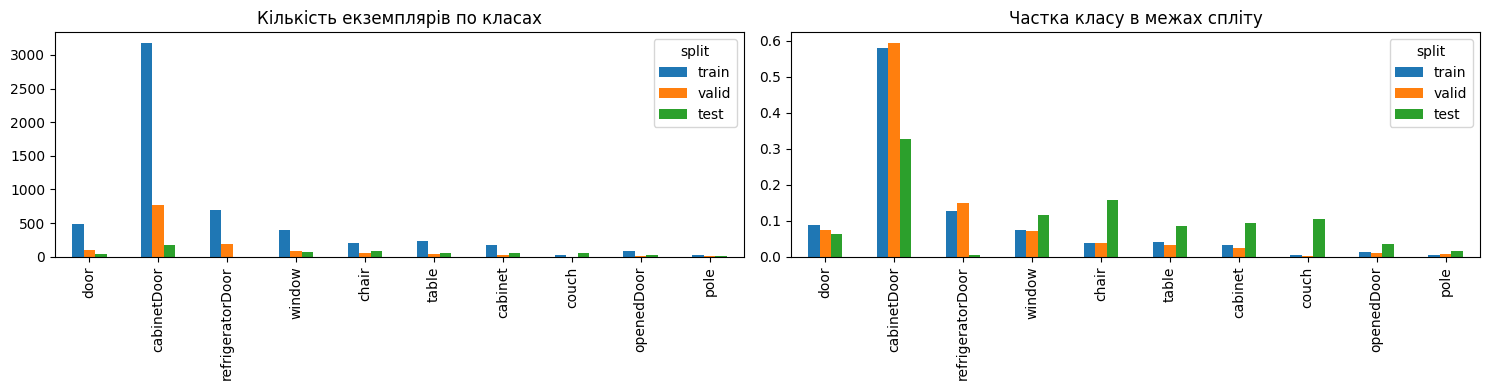

In [5]:
counts = boxes.pivot_table(index='name', columns='split', values='cls', aggfunc='count', fill_value=0)
counts = counts.reindex(CLASS_NAMES)[list(SPLITS)]
display(counts)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
counts.plot.bar(ax=axes[0])
axes[0].set_title('Кількість екземплярів по класах')
axes[0].set_xlabel('')
(counts / counts.sum()).plot.bar(ax=axes[1])
axes[1].set_title('Частка класу в межах спліту')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

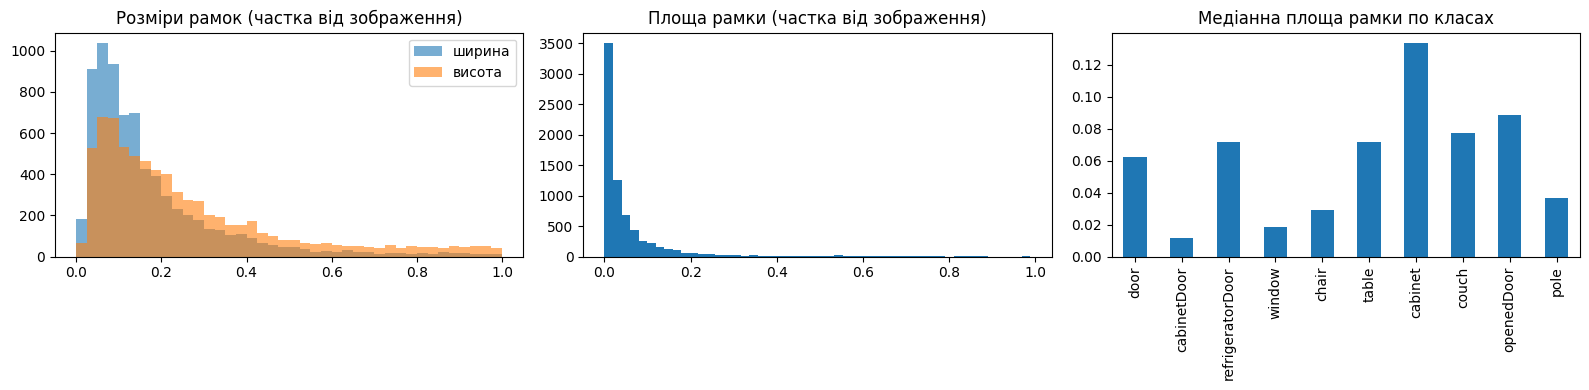

Частка малих рамок (площа < 1% зображення): 0.298
Найчастіші розміри зображень (w, h): {(1024, 768): 55, (768, 1024): 29, (1024, 683): 19, (1024, 681): 8, (620, 460): 6}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(boxes.w, bins=40, alpha=.6, label='ширина')
axes[0].hist(boxes.h, bins=40, alpha=.6, label='висота')
axes[0].set_title('Розміри рамок (частка від зображення)')
axes[0].legend()
axes[1].hist(boxes.area, bins=50)
axes[1].set_title('Площа рамки (частка від зображення)')
boxes.groupby('name').area.median().reindex(CLASS_NAMES).plot.bar(ax=axes[2])
axes[2].set_title('Медіанна площа рамки по класах')
axes[2].set_xlabel('')
plt.tight_layout()
plt.show()

print('Частка малих рамок (площа < 1% зображення):', round((boxes.area < 0.01).mean(), 3))

sizes = []
all_imgs = [p for p in (dataset_path / 'train' / 'images').iterdir() if p.is_file()]
for p in random.sample(all_imgs, 200):
    with Image.open(p) as im:
        sizes.append(im.size)
print('Найчастіші розміри зображень (w, h):', pd.Series(sizes).value_counts().head(5).to_dict())

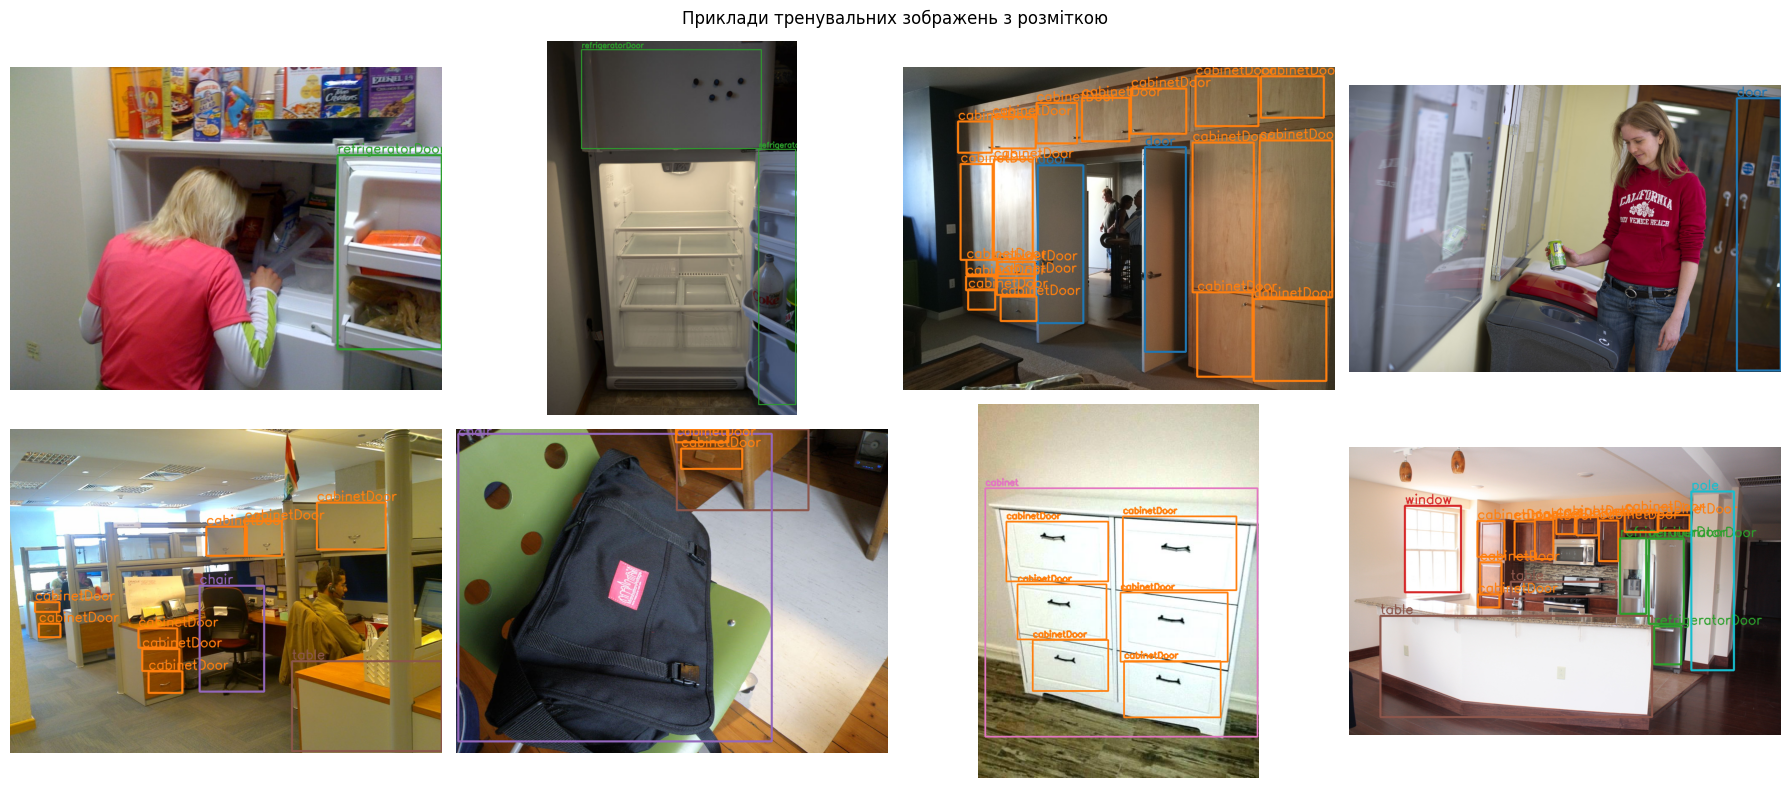

In [7]:
COLORS = plt.cm.tab10(np.linspace(0, 1, NC))[:, :3] * 255


def find_image(split, stem):
    for p in (dataset_path / split / 'images').glob(stem + '.*'):
        return p


def draw_gt(split, stem):
    img = cv2.cvtColor(cv2.imread(str(find_image(split, stem))), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for _, r in boxes[(boxes.split == split) & (boxes.file == stem)].iterrows():
        x1, y1 = int((r.xc - r.w / 2) * w), int((r.yc - r.h / 2) * h)
        x2, y2 = int((r.xc + r.w / 2) * w), int((r.yc + r.h / 2) * h)
        color = tuple(int(c) for c in COLORS[int(r.cls)])
        cv2.rectangle(img, (x1, y1), (x2, y2), color, max(2, w // 300))
        cv2.putText(img, r['name'], (x1, max(y1 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, max(.5, w / 1000), color, 2)
    return img


stems = random.sample(sorted(boxes[boxes.split == 'train'].file.unique()), 8)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, stem in zip(axes.ravel(), stems):
    ax.imshow(draw_gt('train', stem))
    ax.axis('off')
plt.suptitle('Приклади тренувальних зображень з розміткою')
plt.tight_layout()
plt.show()

**Спостереження за даними** (див. таблиці й графіки вище):
- датасет невеликий (≈1 тис. зображень у train), тому важливий transfer learning з попередньо навчених ваг;
- сильний дисбаланс класів: `cabinetDoor` домінує, а `couch`, `pole`, `openedDoor` мають лише десятки екземплярів у train;
- розподіл класів між train / valid / test різний (наприклад, `couch` рідкісний у train, але частий у test; `refrigeratorDoor` у test майже відсутній), тому метрики на test для окремих класів будуть нестабільними;
- частина зображень має порожню розмітку (фонові приклади) — це нормально для YOLO.

## 4. Конфігурація YOLO (YAML) і вибір моделі

**Чому YOLOv9s:**
- одностадійний детектор: швидкий інференс, простий пайплайн навчання;
- архітектура GELAN + PGI зменшує втрату інформації в глибоких шарах — добре для малих датасетів;
- версія `s` (≈7 млн параметрів) — компроміс між точністю та пам'яттю: вміщується в безкоштовний GPU, швидко навчається, і менше схильна до перенавчання на ≈1 тис. зображень, ніж `m`/`c`/`e`;
- є ваги, попередньо навчені на COCO (в ньому вже є `chair`, `couch`, `dining table`, `refrigerator`), тож backbone вже вміє виділяти релевантні ознаки.

In [8]:
data_cfg = {
    'path': str(dataset_path),
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': NC,
    'names': {i: n for i, n in enumerate(CLASS_NAMES)},
}
DATA_YAML = Path('indoor_objects.yaml').resolve()
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())

path: /kaggle/input/datasets/thepbordin/indoor-object-detection
train: train/images
val: valid/images
test: test/images
nc: 10
names:
  0: door
  1: cabinetDoor
  2: refrigeratorDoor
  3: window
  4: chair
  5: table
  6: cabinet
  7: couch
  8: openedDoor
  9: pole



## 5. Навчання моделі

Параметри: попередньо навчені ваги COCO, `imgsz=640`, стандартні аугментації Ultralytics (mosaic, HSV, flip, scale), early stopping (`patience`). Найкращі ваги за fitness (`0.1·mAP50 + 0.9·mAP50-95`) зберігаються в `weights/best.pt`.

In [9]:
model = YOLO(MODEL_NAME)
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    fraction=FRACTION,
    device=DEVICE,
    workers=2,
    seed=SEED,
    project='runs',
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)
SAVE_DIR = Path(model.trainer.save_dir)
BEST_PT = SAVE_DIR / 'weights' / 'best.pt'
print('Результати збережено в', SAVE_DIR)
print('Найкращі ваги:', BEST_PT, '| існує:', BEST_PT.exists())

Ultralytics 8.4.188 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/indoor_objects.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov9s_indoor, nbs=64, nms=None, opset=None, optimize

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      6.47G      1.466      1.914      1.413         28        640: 100% ━━━━━━━━━━━━ 64/64 4.0it/s 16.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.8it/s 2.1s
                   all        230       1289      0.548      0.305      0.321      0.207

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      6.47G       1.48      1.825      1.431         18        640: 100% ━━━━━━━━━━━━ 64/64 3.9it/s 16.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.0it/s 2.0s
                   all        230       1289      0.418      0.315      0.248      0.138

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      6.47G      1.474      1.768      1.434         30        640: 100% ━━━━━━━━━━━━ 64/64 4.0it/s 16.2s
                 Class     Images  Instances      Box(P        

## 6. Аналіз кривих навчання

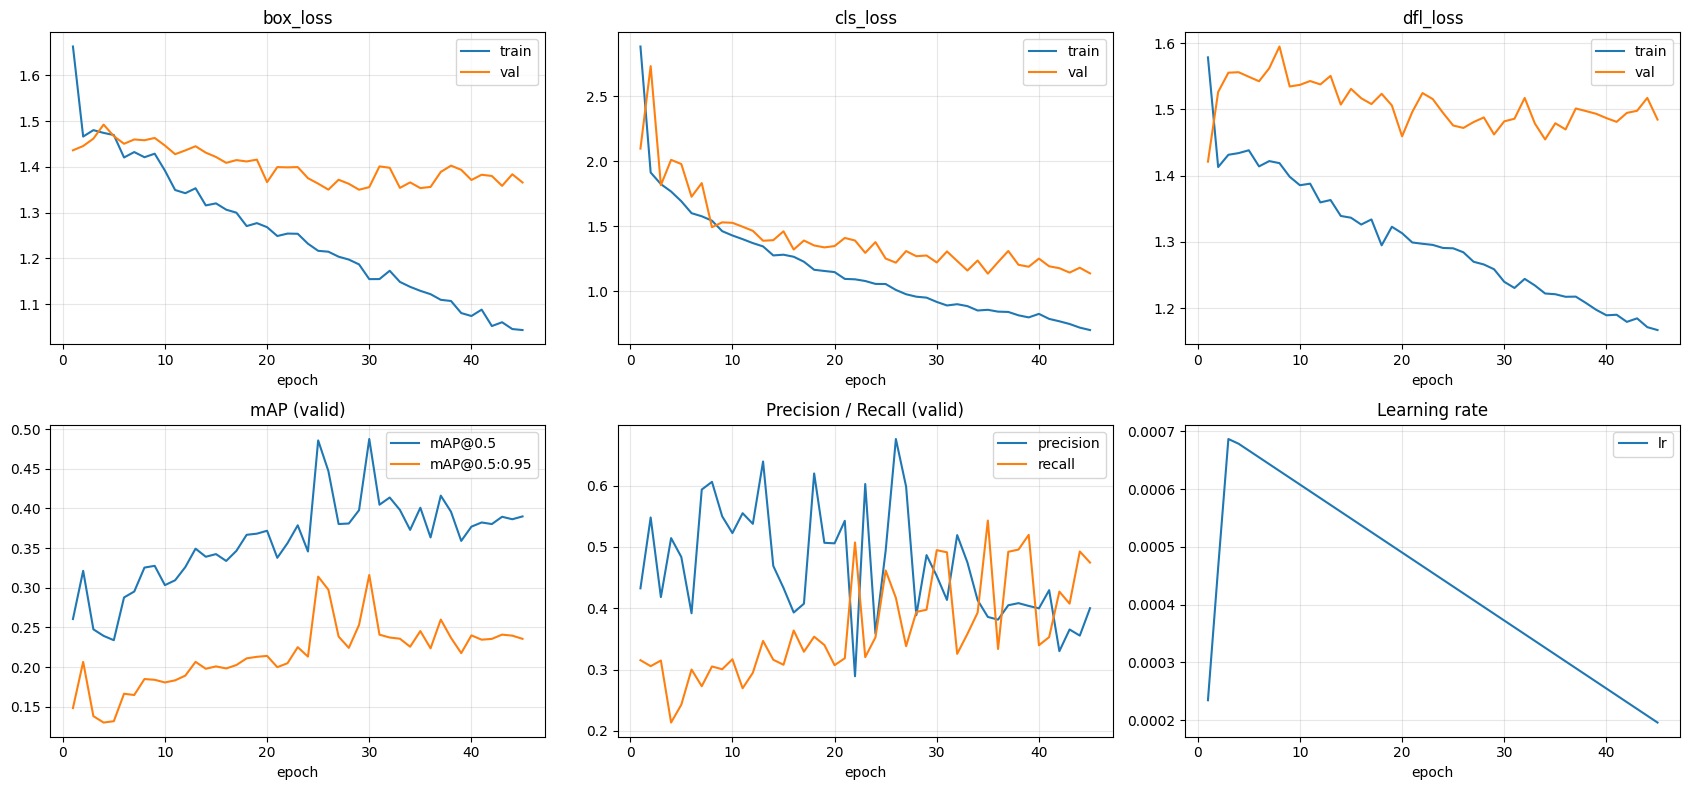

In [10]:
hist = pd.read_csv(SAVE_DIR / 'results.csv')
hist.columns = hist.columns.str.strip()
x = hist['epoch']

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, loss in zip(axes[0], ['box_loss', 'cls_loss', 'dfl_loss']):
    ax.plot(x, hist[f'train/{loss}'], label='train')
    ax.plot(x, hist[f'val/{loss}'], label='val')
    ax.set_title(loss)
    ax.set_xlabel('epoch')
    ax.legend()
    ax.grid(alpha=.3)

axes[1, 0].plot(x, hist['metrics/mAP50(B)'], label='mAP@0.5')
axes[1, 0].plot(x, hist['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
axes[1, 0].set_title('mAP (valid)')
axes[1, 1].plot(x, hist['metrics/precision(B)'], label='precision')
axes[1, 1].plot(x, hist['metrics/recall(B)'], label='recall')
axes[1, 1].set_title('Precision / Recall (valid)')
axes[1, 2].plot(x, hist['lr/pg0'], label='lr')
axes[1, 2].set_title('Learning rate')
for ax in axes[1]:
    ax.set_xlabel('epoch')
    ax.legend()
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

In [11]:
loss_cols = ['box_loss', 'cls_loss', 'dfl_loss']
hist['train_total'] = hist[[f'train/{c}' for c in loss_cols]].sum(axis=1)
hist['val_total'] = hist[[f'val/{c}' for c in loss_cols]].sum(axis=1)
hist['fitness'] = 0.1 * hist['metrics/mAP50(B)'] + 0.9 * hist['metrics/mAP50-95(B)']

best_ep = int(hist['fitness'].idxmax())
min_val_ep = int(hist['val_total'].idxmin())
last = hist.iloc[-1]

print(f'Епох виконано: {len(hist)} з {EPOCHS}' + (' (early stopping)' if len(hist) < EPOCHS else ''))
print(f'Найкраща епоха за fitness: {int(hist.loc[best_ep, "epoch"])} '
      f'(mAP50={hist.loc[best_ep, "metrics/mAP50(B)"]:.3f}, mAP50-95={hist.loc[best_ep, "metrics/mAP50-95(B)"]:.3f})')
print(f'Мінімум val loss на епосі: {int(hist.loc[min_val_ep, "epoch"])}')
print(f'Останнє значення: train loss = {last.train_total:.3f}, val loss = {last.val_total:.3f}, '
      f'розрив = {last.val_total - last.train_total:+.3f}')

if len(hist) < 5:
    print('=> замало епох для висновку про перенавчання.')
elif last.val_total > hist.val_total.min() * 1.05 and last.train_total < hist.train_total.iloc[min_val_ep]:
    print('=> val loss піднялась від свого мінімуму, поки train loss падає: ознаки ПЕРЕНАВЧАННЯ.')
elif last.train_total > 1.0 and last.val_total > 1.0 and len(hist) >= EPOCHS:
    print('=> обидві втрати ще високі й падають: можливе НЕДОНАВЧАННЯ (потрібно більше епох).')
else:
    print('=> суттєвого перенавчання не видно: val loss тримається поблизу мінімуму.')

Епох виконано: 45 з 60 (early stopping)
Найкраща епоха за fitness: 30 (mAP50=0.487, mAP50-95=0.316)
Мінімум val loss на епосі: 35
Останнє значення: train loss = 2.912, val loss = 3.988, розрив = +1.077
=> суттєвого перенавчання не видно: val loss тримається поблизу мінімуму.


**Як читати криві:**
- train-втрати падають монотонно; якщо val-втрати розвертаються вгору при подальшому падінні train — це перенавчання (на ≈1 тис. зображень воно очікуване на пізніх епохах);
- якщо обидві криві ще падають наприкінці навчання — недонавчання, потрібно більше епох;
- валідаційні метрики mAP зазвичай «шумлять» між епохами, бо valid містить лише 230 зображень, а рідкісні класи мають по кілька екземплярів. Тому best-епоха обирається за fitness, а не за останньою епохою.

## 7. Оцінка на валідаційному та тестовому наборах

In [12]:
best_model = YOLO(BEST_PT)


def evaluate(split):
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                       project='runs', name=f'eval_{split}', exist_ok=True, plots=True, verbose=False)
    per_class = pd.DataFrame(index=CLASS_NAMES, columns=['instances', 'precision', 'recall', 'f1', 'AP50', 'AP50-95'],
                             dtype=float)
    n_inst = boxes[boxes.split == ('valid' if split == 'val' else split)].groupby('name').size()
    per_class['instances'] = n_inst.reindex(CLASS_NAMES).fillna(0).astype(int)
    for k, ci in enumerate(m.box.ap_class_index):
        per_class.iloc[ci, 1:] = [m.box.p[k], m.box.r[k], m.box.f1[k], m.box.ap50[k], m.box.ap[k]]
    overall = {'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map,
               'F1 (macro)': per_class['f1'].mean()}
    return m, per_class, overall


val_m, val_cls, val_overall = evaluate('val')
test_m, test_cls, test_overall = evaluate('test')

summary = pd.DataFrame({'valid': val_overall, 'test': test_overall}).round(3)
print('Загальні метрики (precision/recall/F1 - при порозі confidence, що максимізує F1):')
display(summary)
print('\nМетрики по класах, VALID:')
display(val_cls.round(3))
print('\nМетрики по класах, TEST:')
display(test_cls.round(3))

Ultralytics 8.4.188 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 428.2±282.3 MB/s, size: 238.7 KB)
val: Scanning /kaggle/input/datasets/thepbordin/indoor-object-detection/valid/labels... 230 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 853.2it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/thepbordin/indoor-object-detection/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.5it/s 4.3s
                   all        230       1289      0.465      0.495      0.488      0.316
Speed: 1.6ms preprocess, 9.7ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /kaggle/working/runs/detect/runs/eval_val
Ultralytics 8.4.188 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9s s

,valid,test
precision,0.465,0.544
recall,0.495,0.309
mAP50,0.488,0.331
mAP50-95,0.316,0.189
F1 (macro),0.466,0.338



Метрики по класах, VALID:


,instances,precision,recall,f1,AP50,AP50-95
door,97,0.403,0.495,0.444,0.463,0.284
cabinetDoor,765,0.809,0.782,0.796,0.835,0.475
refrigeratorDoor,192,0.732,0.776,0.753,0.798,0.522
window,91,0.404,0.407,0.405,0.310,0.175
chair,49,0.621,0.570,0.594,0.568,0.275
table,40,0.241,0.125,0.165,0.209,0.120
cabinet,32,0.370,0.594,0.456,0.437,0.320
couch,1,0.634,1.000,0.776,0.995,0.896
openedDoor,13,0.108,0.094,0.101,0.098,0.040
pole,9,0.330,0.111,0.166,0.173,0.053



Метрики по класах, TEST:


,instances,precision,recall,f1,AP50,AP50-95
door,34,0.513,0.265,0.349,0.272,0.153
cabinetDoor,179,0.545,0.475,0.508,0.457,0.164
refrigeratorDoor,2,0.665,0.996,0.797,0.828,0.596
window,63,0.674,0.540,0.600,0.585,0.345
chair,87,0.579,0.363,0.446,0.361,0.188
table,47,0.363,0.106,0.165,0.138,0.064
cabinet,52,0.522,0.212,0.301,0.273,0.178
couch,58,0.301,0.086,0.134,0.134,0.054
openedDoor,20,0.274,0.050,0.085,0.190,0.099
pole,8,1.000,0.000,0.000,0.070,0.052


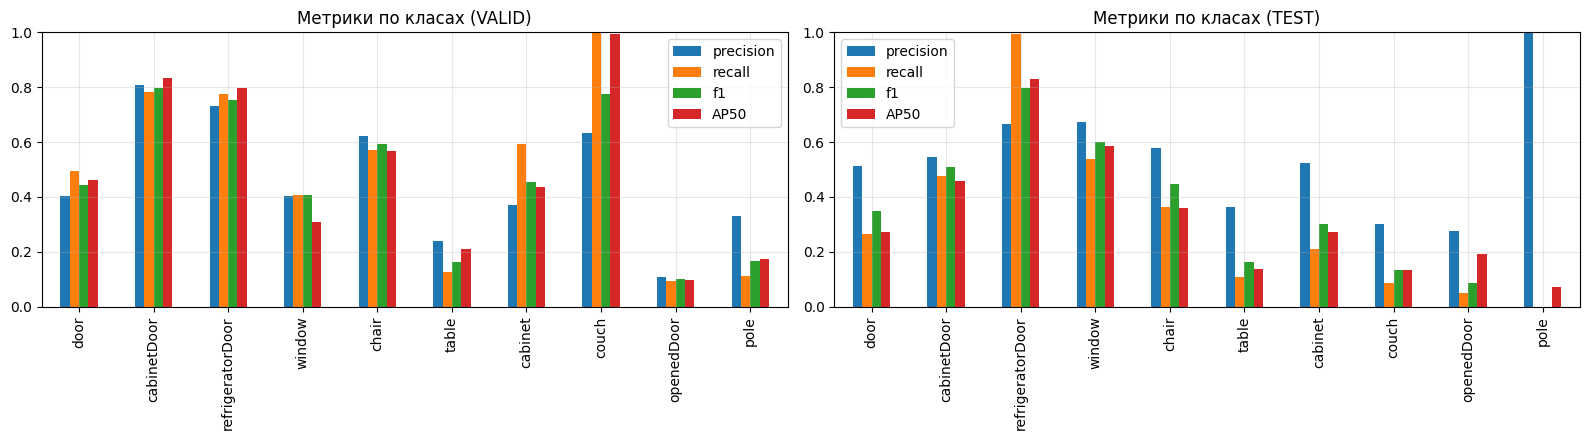

VALID: найкращі класи (AP50): couch (0.99), cabinetDoor (0.83), refrigeratorDoor (0.80)
VALID: найгірші класи (AP50): table (0.21), pole (0.17), openedDoor (0.10)
TEST: найкращі класи (AP50): refrigeratorDoor (0.83), window (0.58), cabinetDoor (0.46)
TEST: найгірші класи (AP50): table (0.14), couch (0.13), pole (0.07)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (title, df) in zip(axes, [('VALID', val_cls), ('TEST', test_cls)]):
    df[['precision', 'recall', 'f1', 'AP50']].plot.bar(ax=ax)
    ax.set_title(f'Метрики по класах ({title})')
    ax.set_ylim(0, 1)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

for title, df in [('VALID', val_cls), ('TEST', test_cls)]:
    ranked = df[df.instances > 0].sort_values('AP50', ascending=False)
    print(f'{title}: найкращі класи (AP50):', ', '.join(f'{n} ({v:.2f})' for n, v in ranked.AP50.head(3).items()))
    print(f'{title}: найгірші класи (AP50):', ', '.join(f'{n} ({v:.2f})' for n, v in ranked.AP50.tail(3).items()))

## 8. Матриця помилок і міжкласові плутанини

Ultralytics 8.4.188 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 543.4±149.2 MB/s, size: 284.1 KB)
val: Scanning /kaggle/input/datasets/thepbordin/indoor-object-detection/valid/labels... 230 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 898.7it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/thepbordin/indoor-object-detection/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.7it/s 4.1s
                   all        230       1289      0.578       0.48      0.411      0.277
Speed: 1.5ms preprocess, 10.2ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /kaggle/working/runs/detect/runs/cm_val


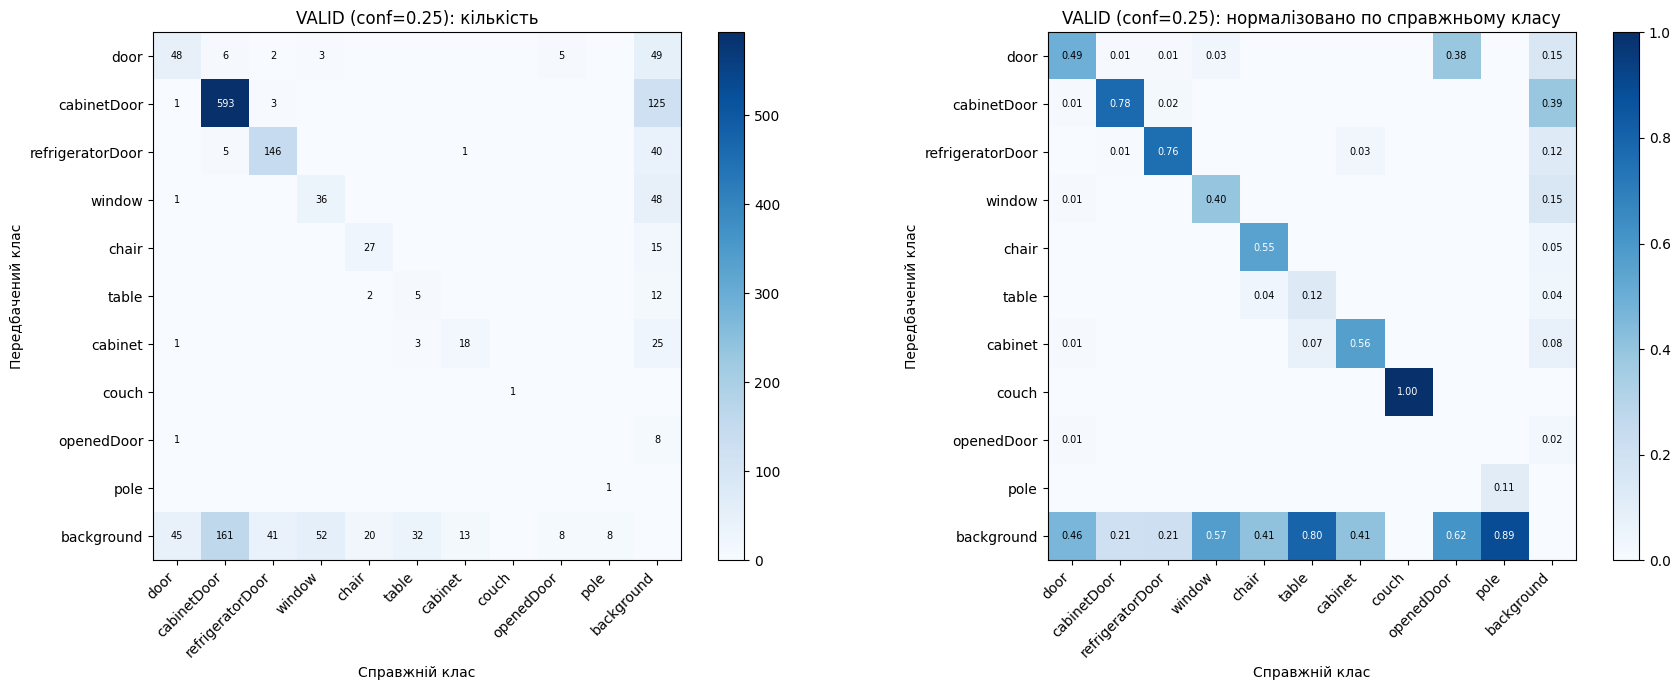

Топ-10 плутанин класів (VALID):


,справжній,передбачено як,кількість,частка від класу
4,cabinetDoor,door,6,0.008
12,openedDoor,door,5,0.385
5,cabinetDoor,refrigeratorDoor,5,0.007
7,refrigeratorDoor,cabinetDoor,3,0.016
8,window,door,3,0.033
10,table,cabinet,3,0.075
6,refrigeratorDoor,door,2,0.010
9,chair,table,2,0.041
0,door,cabinetDoor,1,0.010
3,door,openedDoor,1,0.010


Пропуски та хибні спрацювання відносно фону (VALID):


,"пропущено (FN, predicted=background)","хибні спрацювання (FP, true=background)"
door,45,49
cabinetDoor,161,125
refrigeratorDoor,41,40
window,52,48
chair,20,15
table,32,12
cabinet,13,25
couch,0,0
openedDoor,8,8
pole,8,0


Точність класифікації серед знайдених і зіставлених об'єктів (VALID): 0.963


In [14]:
CM_CONF = 0.25  # робочий поріг; val() для mAP використовує conf=0.001, що роздуло б хибні спрацювання


def confusion_analysis(split, title):
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, conf=CM_CONF,
                       project='runs', name=f'cm_{split}', exist_ok=True, plots=True, verbose=False)  # матриця рахується лише при plots=True
    # У Ultralytics рядки = передбачений клас, стовпці = справжній клас, остання позиція = background
    cm = np.array(m.confusion_matrix.matrix, dtype=float)
    labels = CLASS_NAMES + ['background']
    cm_true_norm = cm / np.maximum(cm.sum(axis=0, keepdims=True), 1)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for ax, data, sub, fmt in [(axes[0], cm, 'кількість', '{:.0f}'), (axes[1], cm_true_norm, 'нормалізовано по справжньому класу', '{:.2f}')]:
        im = ax.imshow(data, cmap='Blues')
        ax.set_xticks(range(NC + 1)); ax.set_xticklabels(labels, rotation=45, ha='right')
        ax.set_yticks(range(NC + 1)); ax.set_yticklabels(labels)
        ax.set_xlabel('Справжній клас'); ax.set_ylabel('Передбачений клас')
        ax.set_title(f'{title} (conf={CM_CONF}): {sub}')
        thr = data.max() / 2
        for i in range(NC + 1):
            for j in range(NC + 1):
                if data[i, j] > 0:
                    ax.text(j, i, fmt.format(data[i, j]), ha='center', va='center', fontsize=7,
                            color='white' if data[i, j] > thr else 'black')
        plt.colorbar(im, ax=ax, fraction=.046)
    plt.tight_layout()
    plt.show()

    pairs = []
    for true in range(NC):
        for pred in range(NC):
            if pred != true and cm[pred, true] > 0:
                pairs.append({'справжній': CLASS_NAMES[true], 'передбачено як': CLASS_NAMES[pred],
                              'кількість': int(cm[pred, true]), 'частка від класу': cm[pred, true] / cm[:, true].sum()})
    pairs = pd.DataFrame(pairs, columns=['справжній', 'передбачено як', 'кількість', 'частка від класу'])
    pairs = pairs.sort_values('кількість', ascending=False)

    per_class = pd.DataFrame({
        'пропущено (FN, predicted=background)': cm[NC, :NC],
        'хибні спрацювання (FP, true=background)': cm[:NC, NC],
    }, index=CLASS_NAMES).astype(int)

    matched = cm[:NC, :NC]
    acc = np.trace(matched) / max(matched.sum(), 1)
    return pairs, per_class, acc


pairs_val, bg_val, acc_val = confusion_analysis('val', 'VALID')
print('Топ-10 плутанин класів (VALID):')
display(pairs_val.head(10).round(3))
print('Пропуски та хибні спрацювання відносно фону (VALID):')
display(bg_val)
print(f'Точність класифікації серед знайдених і зіставлених об\'єктів (VALID): {acc_val:.3f}')

Ultralytics 8.4.188 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 682.8±63.4 MB/s, size: 385.7 KB)
val: Scanning /kaggle/input/datasets/thepbordin/indoor-object-detection/test/labels... 104 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 361.7it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/thepbordin/indoor-object-detection/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.1it/s 2.2s
                   all        107        550      0.458       0.25      0.209      0.127
Speed: 3.1ms preprocess, 8.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/runs/cm_test


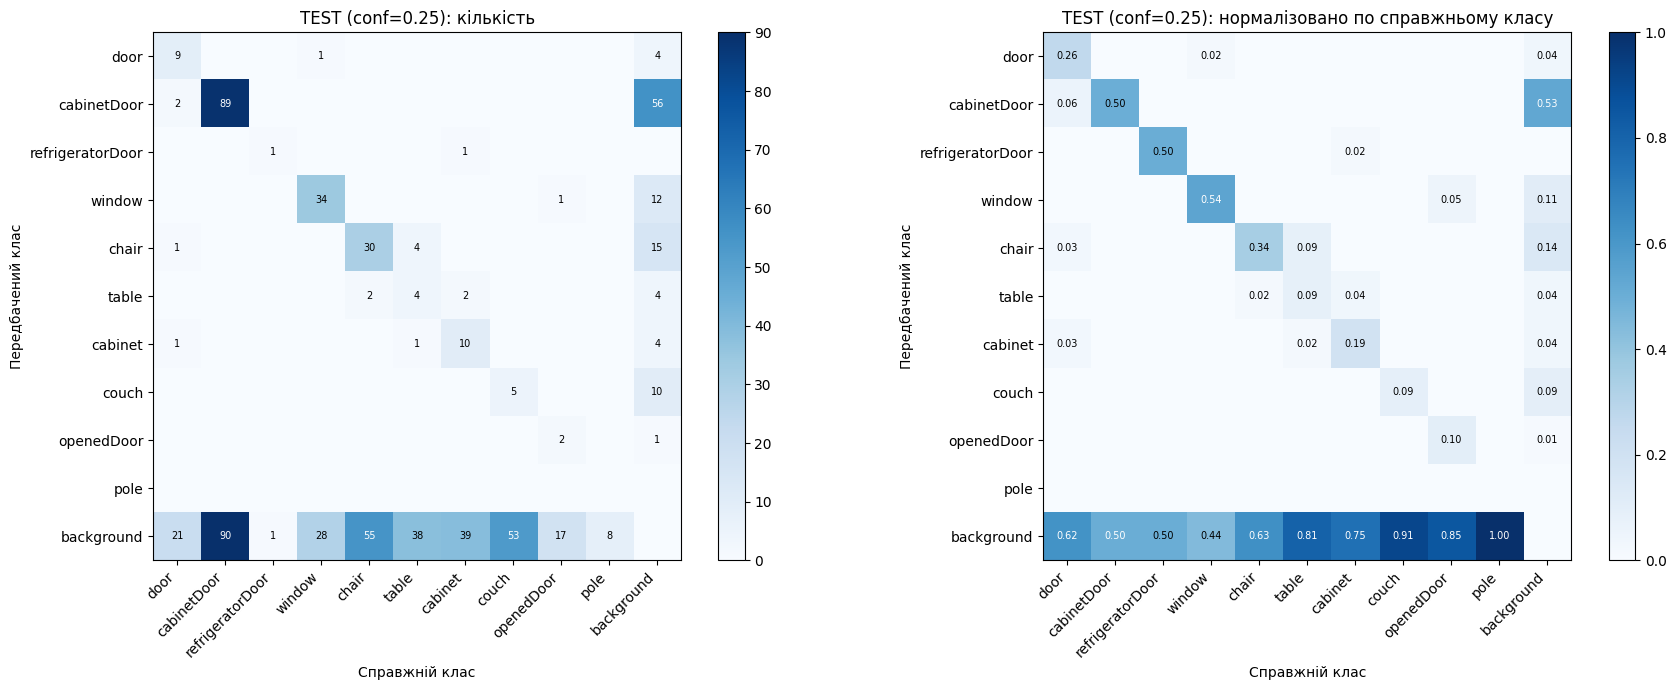

Топ-10 плутанин класів (TEST):


,справжній,передбачено як,кількість,частка від класу
5,table,chair,4,0.085
0,door,cabinetDoor,2,0.059
8,cabinet,table,2,0.038
4,chair,table,2,0.023
1,door,chair,1,0.029
3,window,door,1,0.016
2,door,cabinet,1,0.029
6,table,cabinet,1,0.021
7,cabinet,refrigeratorDoor,1,0.019
9,openedDoor,window,1,0.050


Пропуски та хибні спрацювання відносно фону (TEST):


,"пропущено (FN, predicted=background)","хибні спрацювання (FP, true=background)"
door,21,4
cabinetDoor,90,56
refrigeratorDoor,1,0
window,28,12
chair,55,15
table,38,4
cabinet,39,4
couch,53,10
openedDoor,17,1
pole,8,0


Точність класифікації серед знайдених і зіставлених об'єктів (TEST): 0.920


In [15]:
pairs_test, bg_test, acc_test = confusion_analysis('test', 'TEST')
print('Топ-10 плутанин класів (TEST):')
display(pairs_test.head(10).round(3))
print('Пропуски та хибні спрацювання відносно фону (TEST):')
display(bg_test)
print(f'Точність класифікації серед знайдених і зіставлених об\'єктів (TEST): {acc_test:.3f}')

## 9. Приклади передбачень на тестовому наборі

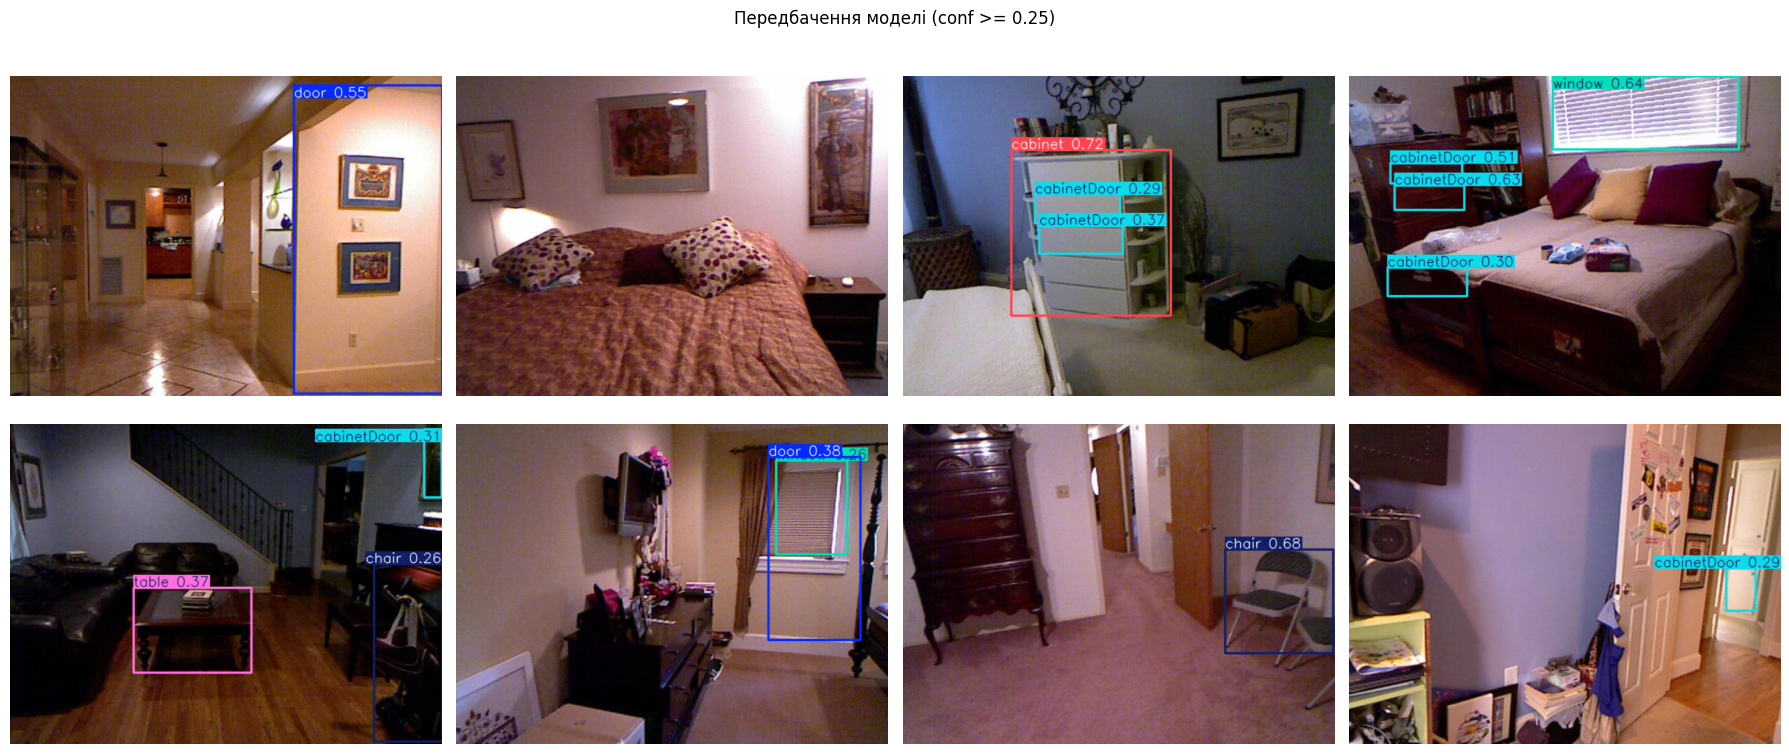

In [16]:
test_imgs = sorted(p for p in (dataset_path / 'test' / 'images').iterdir() if p.is_file())
sample = random.sample(test_imgs, 8)
preds = best_model.predict(sample, imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.suptitle('Передбачення моделі (conf >= 0.25)')
plt.tight_layout()
plt.show()

## 10. Збереження ваг і перевірка мети завдання

In [17]:
FINAL_WEIGHTS = Path('indoor_yolov9s_best.pt')
shutil.copy(BEST_PT, FINAL_WEIGHTS)
print('Ваги збережено:', FINAL_WEIGHTS.resolve(), f'({FINAL_WEIGHTS.stat().st_size / 1e6:.1f} МБ)')

try:  # у Colab: завантажити ваги на локальну машину
    from google.colab import files
    files.download(str(FINAL_WEIGHTS))
except ImportError:
    pass

Ваги збережено: /kaggle/working/indoor_yolov9s_best.pt (15.2 МБ)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
THRESH = 0.5  # клас вважаємо «надійно розпізнаваним», якщо AP@0.5 >= 0.5
need = max(1, round(NC / 3))
key_classes = ['door', 'chair', 'table']

for title, df in [('VALID', val_cls), ('TEST', test_cls)]:
    ok = df[(df.instances > 0) & (df.AP50 >= THRESH)]
    print(f'{title}: класів з AP50 >= {THRESH}: {len(ok)} з {NC} (потрібно щонайменше {need}) ->',
          'МЕТУ ДОСЯГНУТО' if len(ok) >= need else 'мету НЕ досягнуто')
    print('   ', ', '.join(f'{n} ({v:.2f})' for n, v in ok.AP50.sort_values(ascending=False).items()) or '-')
    print('    ключові класи:', ', '.join(f'{c}: {df.loc[c, "AP50"]:.2f}' for c in key_classes))

print()
print('Орієнтири із завдання: mAP50 40-60%, mAP50-95 25-40%, середній F1 45-60%.')
print(f'Отримано (valid): mAP50 = {val_overall["mAP50"]:.1%}, mAP50-95 = {val_overall["mAP50-95"]:.1%}, '
      f'F1 = {val_overall["F1 (macro)"]:.1%}')
print(f'Отримано (test):  mAP50 = {test_overall["mAP50"]:.1%}, mAP50-95 = {test_overall["mAP50-95"]:.1%}, '
      f'F1 = {test_overall["F1 (macro)"]:.1%}')

VALID: класів з AP50 >= 0.5: 4 з 10 (потрібно щонайменше 3) -> МЕТУ ДОСЯГНУТО
    couch (0.99), cabinetDoor (0.83), refrigeratorDoor (0.80), chair (0.57)
    ключові класи: door: 0.46, chair: 0.57, table: 0.21
TEST: класів з AP50 >= 0.5: 2 з 10 (потрібно щонайменше 3) -> мету НЕ досягнуто
    refrigeratorDoor (0.83), window (0.58)
    ключові класи: door: 0.27, chair: 0.36, table: 0.14

Орієнтири із завдання: mAP50 40-60%, mAP50-95 25-40%, середній F1 45-60%.
Отримано (valid): mAP50 = 48.8%, mAP50-95 = 31.6%, F1 = 46.6%
Отримано (test):  mAP50 = 33.1%, mAP50-95 = 18.9%, F1 = 33.8%


## 11. Висновки та рекомендації

> Числа нижче взято з фінального запуску на Kaggle GPU (YOLOv9s, до 60 епох, `imgsz=640`, `batch=16`, early stopping з `patience=15`). Повторний запуск може дати трохи інші значення. Причини помилок, позначені як гіпотези, у ноутбуці не перевірялись.

### 1. Підсумкові метрики

| Метрика | valid | test | Орієнтир із завдання |
|---|---|---|---|
| mAP@0.5 | 0.488 | 0.331 | 0.40-0.60 |
| mAP@0.5:0.95 | 0.316 | 0.189 | 0.25-0.40 |
| Precision | 0.465 | 0.544 | - |
| Recall | 0.495 | 0.309 | 0.50-0.70 |
| F1 (macro) | 0.466 | 0.338 | 0.45-0.60 |
| Точність класифікації серед зіставлених об'єктів | 0.963 | 0.920 | 0.55-0.70 |

На valid mAP@0.5, mAP@0.5:0.95 і F1 потрапляють в орієнтовні діапазони, recall трохи нижчий за нижню межу. На test усі показники нижчі за орієнтири.

### 2. Криві навчання
- Навчання зупинилось за early stopping на **45-й епосі з 60**. Найкраща епоха за fitness — **30** (mAP50 = 0.487, mAP50-95 = 0.316), мінімум val loss — на епосі 35.
- Наприкінці train loss = 2.91, val loss = 3.99 (розрив +1.08). Val loss після мінімуму не росте суттєво, тому **вираженого перенавчання немає**; розрив між train і val типовий для малого датасету.
- **Недонавчання** теж малоймовірне: навчання завершилось не через вичерпання 60 епох, а через відсутність прогресу fitness протягом 15 епох. Подальше покращення потребує змін у даних чи моделі, а не просто більшої кількості епох.

### 3. Метрики по класах

| Клас | Екз. у train | AP50 valid | AP50 test | P / R valid | P / R test |
|---|---|---|---|---|---|
| door | 479 | 0.46 | 0.27 | 0.40 / 0.50 | 0.51 / 0.27 |
| cabinetDoor | 3178 | 0.83 | 0.46 | 0.81 / 0.78 | 0.55 / 0.48 |
| refrigeratorDoor | 689 | 0.80 | 0.83 * | 0.73 / 0.78 | 0.67 / 1.00 * |
| window | 403 | 0.31 | 0.58 | 0.40 / 0.41 | 0.67 / 0.54 |
| chair | 204 | 0.57 | 0.36 | 0.62 / 0.57 | 0.58 / 0.36 |
| table | 228 | 0.21 | 0.14 | 0.24 / 0.13 | 0.36 / 0.11 |
| cabinet | 179 | 0.44 | 0.27 | 0.37 / 0.59 | 0.52 / 0.21 |
| couch | 27 | 0.99 * | 0.13 | 0.63 / 1.00 * | 0.30 / 0.09 |
| openedDoor | 78 | 0.10 | 0.19 | 0.11 / 0.09 | 0.27 / 0.05 |
| pole | 27 | 0.17 | 0.07 | 0.33 / 0.11 | 1.00 / 0.00 |

\* Статистично ненадійні значення: у valid лише 1 екземпляр `couch`, у test лише 2 екземпляри `refrigeratorDoor`.

- **Найкраще:** `cabinetDoor` (F1 0.80 на valid) і `refrigeratorDoor` (F1 0.75 на valid, 0.80 на test). Це найчисленніші класи у train. Стабільно розпізнаються `cabinetDoor` (AP50 0.83 / 0.46) та `window` на test (0.58).
- **Найгірше:** `table` (AP50 0.21 / 0.14, recall 0.13 / 0.11), `openedDoor` (0.10 / 0.19), `pole` (0.17 / 0.07, на test recall 0). `table` має 228 прикладів у train, тобто це не лише питання кількості даних, ймовірно, клас складний сам по собі (гіпотеза: оклюзія, різноманітний вигляд).
- **Найпоширеніші предмети із завдання:** `door` (AP50 0.46 / 0.27), `chair` (0.57 / 0.36), `table` (0.21 / 0.14). Найкраще з трьох працює `chair`, найгірше - `table`.
- Для більшості класів precision на test вища за recall (загалом 0.544 проти 0.309): модель консервативна й пропускає об'єкти при порозі confidence 0.25.

### 4. Матриця помилок
Матриці побудовано при `conf = 0.25`. Серед об'єктів, які модель знайшла й зіставила, клас визначено правильно у **96%** (valid) і **92%** (test) випадків. Отже, основна проблема не плутанина класів, а **пропуски об'єктів (FN)** і хибні спрацювання на фоні (FP).

- **Найбільше пропусків:** `cabinetDoor` (161 на valid, 90 на test), `door` (45 / 21), `window` (52 / 28); на test також `chair` (55), `couch` (53 з 58), `cabinet` (39), `table` (38).
- **Найчастіші плутанини класів:** `openedDoor` -> `door` (5 з 13, 38% класу на valid); `cabinetDoor` -> `door` (6) і `cabinetDoor` <-> `refrigeratorDoor` (5 і 3) на valid; `table` -> `chair` (4, 8.5% класу на test), `table` -> `cabinet`, `cabinet` -> `table`, `chair` -> `table` (по 2-3).
- **Гіпотези причин:** `door`, `openedDoor`, `cabinetDoor`, `refrigeratorDoor` - прямокутні панелі з ручкою, що відрізняються здебільшого контекстом і станом (відчинені/зачинені); `openedDoor` має лише 78 прикладів у train. `table`, `chair`, `cabinet` часто перекривають одне одного, що ускладнює і виявлення, і класифікацію.
- **Хибні спрацювання:** найбільше у `cabinetDoor` (125 на valid, 56 на test), що природно для класу з великою кількістю дрібних схожих екземплярів.

### 5. Чому test гірший за valid
- **Вибір моделі за valid.** `best.pt` і early stopping обрано за valid, тому оцінка на valid трохи оптимістична, а test - незалежна.
- **Різний розподіл класів.** `couch`: 27 у train, 1 у valid, 58 у test; recall на test лише 0.09 (пропущено 53 з 58). `refrigeratorDoor` має 2 екземпляри в test, `chair` - 87 у test проти 49 у valid.
- **Малі вибірки.** Класи з 8-13 екземплярами (`pole`, `openedDoor`, `couch`, `refrigeratorDoor`) дають дуже шумні AP на окремих спліттах.
- Тому метрики окремих класів варто читати разом із кількістю екземплярів, а загальний рівень - орієнтовно між valid і test (mAP@0.5 ~ 0.33-0.49).

### 6. Чи досягнуто мети
- **Критерій AP50 >= 0.5 для щонайменше 3 з 10 класів** (розділ 10): valid - 4 класи (`couch`, `cabinetDoor`, `refrigeratorDoor`, `chair`), але `couch` ненадійний (1 екземпляр), тобто надійно 3; test - 2 класи (`refrigeratorDoor`, `window`), з яких `refrigeratorDoor` ненадійний (2 екземпляри).
- Модель **відчутно розпізнає** `cabinetDoor`, `refrigeratorDoor`, `chair` (valid) і `window` (test), тобто принаймні 3 класи з 10 виявляються. Однак за суворим порогом AP50 >= 0.5 результат на test мету не досягає, а `table` і `door` залишаються слабкими. Висновок: мету досягнуто **частково**, стабільність між спліттами недостатня.

### 7. Критика архітектури
- **Плюси YOLOv9s:** швидка, легка (≈7 млн параметрів), є COCO-ваги з релевантними класами (chair, couch, dining table, refrigerator), простий пайплайн; завдяки transfer learning за ≈45 епох на ≈1 тис. зображень отримано mAP@0.5 = 0.49 на valid.
- **Мінуси:** одностадійний детектор гірше працює з малими й сильно перекритими об'єктами (у нас слабкі `table`, `pole`); чутливий до дисбалансу класів (`cabinetDoor` 3178 проти `couch`/`pole` по 27); `s`-версія має обмежену ємність для дрібних відмінностей між схожими класами (`door` vs `openedDoor`); дефолтні аугментації не враховують специфіку приміщень.

### 8. Шляхи покращення (за пріоритетом; не перевірялись експериментально)
1. **Стратифіковане перерозбиття train/valid/test.** Об'єднати всі ≈1.3 тис. зображень і розділити так, щоб розподіл класів збігався. Це дасть чесніше порівняння valid/test і прибере ситуацію з `couch` (27 / 1 / 58).
2. **Рідкісні класи:** додати зображення `couch`, `pole`, `openedDoor`; oversampling та `copy_paste`-аугментація; перевірити й уніфікувати розмітку неоднозначних класів (`door` / `openedDoor`, `cabinet` / `cabinetDoor`).
3. **Пороги confidence по класах.** Оскільки recall помітно нижчий за precision (test: 0.31 проти 0.54), знижуючи поріг для слабких класів за кривими PR/F1, можна підняти recall.
4. **Навчання:** `imgsz` 800-1024 для дрібних об'єктів, `cos_lr=True`, посилені аугментації (`mixup`, `scale`, `hsv_*`), зважена cls-втрата.
5. **Модель:** YOLOv9m/c або YOLO11m із більшою ємністю; TTA (`augment=True`) на інференсі; ансамбль моделей.
6. **Альтернативи:** трансформерні детектори (RT-DETR, DINO), які краще моделюють контекст і перекриття; сегментація для об'єктів зі складною формою.